# 10 · Coupling at zero frequency: a long-run covariance bank, joint whitening and a fairer baseline

**Where we are.** Notebook 09 found that coupling across slices helps because it cancels *slow, low-frequency* noise that the slices share. The quantity that should govern the gain for a sustained fault in slice $j$ is the coherence at frequency zero:
$$\text{gain}_j = \frac{1}{1 - R^2_{j,\text{DC}}} = \Sigma_{LR,jj}\,(\Sigma_{LR}^{-1})_{jj},$$
with $\Sigma_{LR}$ the long-run covariance (the cross-spectral density at frequency 0). It is about 21 for URLLC and mMTC, against the instantaneous $1/(1-R_j^2) \approx 2.1$. Our CUSUM bank uses the instantaneous $\Sigma$, so it should leave gain on the table.

**Predictions tested here.**
- **P1.** A bank whose matched filter uses $\Sigma_{LR}^{-1}$ is faster than the bank using $\Sigma^{-1}$ on slice-local faults.
- **P2.** Whitening the slices *jointly* with a vector autoregression (VAR) and running the bank on its innovations is at least as fast. In theory both have the same long-run rate: for a step shift $\mu$, the VAR innovations shift by $A(1)\mu$ with $A(1) = I - \sum_\ell A_\ell$, and $\mu^\top A(1)^\top \Sigma_e^{-1} A(1)\mu = \mu^\top \Sigma_{LR}^{-1}\mu$. The VAR version has white increments, so the CUSUM is closer to optimal.
- **P3 (fairness).** Richer *per-slice* whitening (AR($p$) per slice) does **not** close the gap. A step fault's long-run rate on one stream is $\mu_j^2/\Sigma_{LR,jj}$ whatever invertible filter is applied to that stream; only other slices can remove the shared slow noise.

**Prior art (checked by web search, Oct 27; abstracts and citing sources, not full texts).**
- **Charting the residuals of a fitted multivariate time-series model** is established in statistical process control for auto- and cross-correlated data. Examples: Vanhatalo et al. (QREI 2015), Hotelling $T^2$ on VAR residuals; Lee, Park & Lee (PHM Asia-Pacific 2017), a multivariate CUSUM for auto- and cross-correlated observations (a search summary says it uses VAR residuals; not confirmed from the full text). So the P2 detector is *not* new.
- **Long-run covariance in sequential monitoring** is standard in econometrics: for example Otto & Breitung, *Backward CUSUM* (Econometric Theory, arXiv 2003.02682). Keshavarz, Scott & Nguyen (arXiv 1506.01338) show that the optimal mean-change test for a Gaussian process uses its covariance structure.
- **What may be new is the application and the explanation.** Shared-resource slicing makes slice KPIs only modestly correlated instant by instant (0.4–0.7), but almost perfectly coherent at low frequency. Instantaneous-correlation reasoning then underestimates the value of coupling by about 10×. We found no slicing paper that says this, but a search cannot prove absence.

**Set-up.** The latency of the three slices, the same simulator, training and calibration runs, fault scenarios and seeds as notebooks 05–09, every detector calibrated to ARL 1000 windows (100 s), the fault at 10 s, 32 runs per case.

In [1]:
import time
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from slicead.sim import Fault, load_config, load_fault_scenarios, simulate
from slicead.detectors import (CUSUM, CUSUMBank, StreamModel, VARModel, candidate_directions, long_run_cov,
                               stream_array)
from slicead.eval import calibrate_bank, calibrate_per_stream, first_alarms, summarize_delays

SEED = 20261022                       # same seeds as notebooks 05-09
OUT = Path("../results/10_long_run_coupling")
OUT.mkdir(parents=True, exist_ok=True)
REPORT = Path("../report")
for sub in ("figures", "tables"):                      # report/ is not in the public repository
    (REPORT / sub).mkdir(parents=True, exist_ok=True)

def save_fig(fig, name):
    fig.savefig(OUT / f"{name}.png", bbox_inches="tight")
    fig.savefig(REPORT / "figures" / f"10_{name}.pdf", bbox_inches="tight")

def save_tex_table(df, name, column_format):
    (REPORT / "tables" / f"10_{name}.tex").write_text(
        df.to_latex(index=False, escape=False, column_format=column_format), encoding="utf-8")

def save_tex_numbers(numbers, name="numbers"):
    lines = [f"\\newcommand{{\\{k}}}{{{v}}}" for k, v in numbers.items()]
    (REPORT / "tables" / f"10_{name}.tex").write_text("\n".join(lines) + "\n", encoding="utf-8")

SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": INK2, "ytick.color": INK2,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": GRID, "grid.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "lines.linewidth": 2, "lines.markersize": 6, "font.size": 10,
    "legend.frameon": False, "figure.dpi": 110, "savefig.dpi": 150,
})

cfg = load_config("../configs/sim_default.yaml")
SLICES = ["eMBB", "URLLC", "mMTC"]
LAT = [(s, "latency_ms") for s in SLICES]
TARGET_ARL, CHANGE_S, HORIZON_W = 1000, 10.0, 300
STRENGTHS = [0.03, 0.1, 0.25, 0.5, 1.0]

## 1. Fault-free models and the zero-frequency coherence

Three models of the fault-free latency streams, all fitted once on the training runs:
- **AR(1) per slice** (`StreamModel`, as in notebooks 05–09) gives the whitened streams $z$.
- **AR($p$) per slice** (`VARModel(diagonal=True)`) has its order chosen by BIC, up to 30 lags (3 s).
- **VAR($p$) across slices** (`VARModel`) whitens the slices jointly, order by BIC.

From $z$ we estimate $\Sigma_{LR}$ with Bartlett weights and $L$ = 25, 50 and 100 lags, and compute each slice's zero-frequency gain $\Sigma_{LR,jj}(\Sigma_{LR}^{-1})_{jj}$. We also compute the gain the VAR implies through $\Sigma_{LR} = A(1)^{-1}\Sigma_e A(1)^{-\top}$.

In [2]:
t0 = time.time()
train = simulate(cfg, n_windows=3000, n_runs=8, seed=SEED)
calib = simulate(cfg, n_windows=3000, n_runs=32, seed=SEED + 1)
Xtr, Xcal = stream_array(train, LAT), stream_array(calib, LAT)
print(f"simulated in {time.time() - t0:.0f} s")

ar1 = StreamModel().fit(Xtr)
arp = VARModel(max_p=30, diagonal=True).fit(Xtr)
var = VARModel(max_p=30).fit(Xtr)
Ztr = ar1.whiten(Xtr)
Sigma = np.corrcoef(Ztr.reshape(-1, 3).T)
SLR = {L: long_run_cov(Ztr, L) for L in (25, 50, 100)}
Ainv = np.linalg.inv(var.dc_gain)
SLR_var = Ainv @ (var.Sigma_e * np.outer(var.sd_e, var.sd_e)) @ Ainv.T

def gain_of(S):
    return np.diag(S) * np.diag(np.linalg.inv(S))

coh = pd.DataFrame({"slice": SLICES, "instantaneous": gain_of(Sigma),
                    **{f"DC, L = {L}": gain_of(S) for L, S in SLR.items()}, "DC, VAR-implied": gain_of(SLR_var)})
print(f"BIC orders: AR(p) per slice p = {arp.p}, VAR p = {var.p}")
print("long-run variance of the residuals (1 = white):",
      "AR(1)", np.round(np.diag(long_run_cov(Ztr, 50)), 2),
      "| AR(p)", np.round(np.diag(long_run_cov(arp.whiten(Xtr), 50)), 2),
      "| VAR", np.round(np.diag(long_run_cov(var.whiten(Xtr), 50)), 2))
coh.round(1)

simulated in 62 s


BIC orders: AR(p) per slice p = 3, VAR p = 3
long-run variance of the residuals (1 = white): AR(1) [0.72 1.32 1.06] | AR(p) [1.01 1.06 1.05] | VAR [1.   1.01 1.04]


,slice,instantaneous,"DC, L = 25","DC, L = 50","DC, L = 100","DC, VAR-implied"
0,eMBB,1.3,2.4,2.5,2.5,2.8
1,URLLC,2.1,16.2,20.1,22.2,26.1
2,mMTC,2.3,17.5,21.6,23.9,28.0


**What Section 1 shows**

- **The slices are far more coherent at low frequency than instant by instant.** For URLLC and mMTC the instantaneous gain $1/(1-R^2)$ is 2.1–2.3. At frequency zero it is about 20–22 ($L = 50$), or 26–28 from the VAR's implied $\Sigma_{LR}$. In terms of coherence, $R^2_{\text{DC}} \approx 0.95$: about 95% of the slow noise in one slice's latency is predictable from the other two.
- **The estimate grows with the lag window** (16–18 at $L = 25$, 22–24 at $L = 100$), as expected of a Bartlett estimate of a quantity driven by slow noise. The VAR estimate is the largest. The theory therefore predicts a gain of *about 20, give or take 30%*, not an exact number.
- **BIC picks only 3 lags for both AR($p$) and VAR**, and both leave nearly white residuals (long-run variance 1.0–1.06). The VAR's residuals are white *per slice*, yet its implied $\Sigma_{LR}$ keeps the cross-slice coherence: that is held in the cross-coefficients and $A(1)$, which the bank uses.

## 2. Five detectors, one false-alarm rate

| detector | input | matched filter |
|---|---|---|
| per-slice CUSUM, AR(1) | $z$ | each slice alone (notebooks 05–08 baseline) |
| per-slice CUSUM, AR($p$) | AR($p$) residuals | each slice alone, richer whitening (P3) |
| bank, $\Sigma$ | $z$ | $\Sigma^{-1}d$, instantaneous (notebook 07) |
| bank, $\Sigma_{LR}$ | $z$ | $\Sigma_{LR}^{-1}d$, zero-frequency (P1) |
| bank, VAR | VAR innovations | $\Sigma_e^{-1}A(1)d$ (P2; residual MCUSUM, prior art) |

All banks use the same 20 candidate directions $d$ (each slice, all, each pair with both signs) and the same equalised calibration. For the $\Sigma_{LR}$ bank the increment is $z^\top\Sigma_{LR}^{-1}d - \tfrac12$ with $d^\top\Sigma_{LR}^{-1}d = 1$, so it has unit *long-run* variance. Its increments are still autocorrelated, which the simulated calibration accounts for.

In [3]:
C = candidate_directions(3)
Zcal, Pcal, Vcal = ar1.whiten(Xcal), arp.whiten(Xcal), var.whiten(Xcal)
INPUTS = {"z": ar1.whiten, "p": arp.whiten, "v": var.whiten}

t0 = time.time()
DET = {}
d = CUSUM(0.5); DET["per-slice, AR(1)"] = (d, calibrate_per_stream(d, Zcal, TARGET_ARL)[0], "z")
d = CUSUM(0.5); DET["per-slice, AR(p)"] = (d, calibrate_per_stream(d, Pcal, TARGET_ARL)[0], "p")
d = CUSUMBank(C, Sigma); DET["bank, Sigma"] = (d, calibrate_bank(d, Zcal, TARGET_ARL)[0], "z")
d = CUSUMBank(C, SLR[50]); DET["bank, Sigma_LR"] = (d, calibrate_bank(d, Zcal, TARGET_ARL)[0], "z")
d = CUSUMBank(var.residual_directions(C), var.Sigma_e); DET["bank, VAR"] = (d, calibrate_bank(d, Vcal, TARGET_ARL)[0], "v")
print(f"calibrated in {time.time() - t0:.0f} s")
for name, (det, c, _) in DET.items():
    sc = det.scale
    print(f"{name:18s} final factor {c:.2f}; per-stream/candidate thresholds {sc.min():.1f} - {sc.max():.1f}")

calibrated in 134 s
per-slice, AR(1)   final factor 0.91; per-stream/candidate thresholds 8.4 - 11.8
per-slice, AR(p)   final factor 0.90; per-stream/candidate thresholds 8.4 - 14.1
bank, Sigma        final factor 0.98; per-stream/candidate thresholds 3.4 - 16.7
bank, Sigma_LR     final factor 0.93; per-stream/candidate thresholds 8.7 - 22.2
bank, VAR          final factor 0.89; per-stream/candidate thresholds 4.1 - 19.4


## 3. Fault-magnitude sweep

Six scenarios (the URLLC loss burst is left out, as in notebook 07, since latency cannot see it) at five strengths $s$, with the same seeds as notebooks 05 and 07. The mean delay counts a miss within 30 s as 30 s. The local-fault inputs are kept for the sensitivity check in Section 5.

In [4]:
SCEN = load_fault_scenarios("../configs/faults.yaml", start_s=CHANGE_S)
ALL = list(SCEN)
NICE = {"capacity_drop": "capacity drop", "capacity_degradation": "capacity degradation",
        "embb_surge": "eMBB surge", "urllc_surge": "URLLC surge", "mmtc_storm": "mMTC storm",
        "urllc_weight_misconfig": "URLLC weight misconfig."}
USE = ["urllc_surge", "mmtc_storm", "urllc_weight_misconfig", "capacity_drop", "capacity_degradation", "embb_surge"]
LOCAL = {"urllc_surge": 1, "mmtc_storm": 2, "urllc_weight_misconfig": 1}     # scenario -> faulted slice

rows, kept = [], {}
t0 = time.time()
for scen in USE:
    i = ALL.index(scen)
    for j, s in enumerate(STRENGTHS):
        res = simulate(cfg, n_windows=400, n_runs=32, seed=SEED + 100 + 10 * i + j,
                       faults=[Fault(f.kind, f.start_s, f.factor ** s, f.slice, f.ramp_s) for f in SCEN[scen]])
        X = stream_array(res, LAT)
        inp = {k: f(X) for k, f in INPUTS.items()}
        if scen in LOCAL:
            kept[(scen, s)] = (inp["z"], res.fault_window)
        for name, (det, c, key) in DET.items():
            t, _ = first_alarms(det, inp[key], c)
            rows.append(dict(scenario=NICE[scen], strength=s, detector=name,
                             **summarize_delays(t, res.fault_window, HORIZON_W, res.window_s)))
sweep = pd.DataFrame(rows)
sweep.to_csv(OUT / "sweep.csv", index=False)
print(f"simulated and scored in {time.time() - t0:.0f} s")
DETS = list(DET)
pd.set_option("display.width", 200)
sweep.pivot_table(index=["scenario", "strength"], columns="detector", values="delay_mean_s")[DETS].round(2)

simulated and scored in 186 s


detector                          per-slice, AR(1)  per-slice, AR(p)  bank, Sigma  bank, Sigma_LR  bank, VAR
scenario                strength                                                                            
URLLC surge             0.03                 26.85             27.04        23.32           13.11       7.70
                        0.10                 11.60             14.46         3.33            0.87       0.62
                        0.25                  1.42              1.40         0.23            0.21       0.24
                        0.50                  0.23              0.18         0.10            0.10       0.10
                        1.00                  0.10              0.10         0.10            0.10       0.10
URLLC weight misconfig. 0.03                 26.24             26.29        16.92            2.33       1.63
                        0.10                  7.50              8.71         0.40            0.27       0.31
                        0.25                  0.64              0.61         0.10            0.10       0.12
                        0.50                  0.13              0.11         0.10            0.10       0.10
                        1.00                  0.10              0.10         0.10            0.10       0.10
capacity degradation    0.03                 27.03             27.63        28.07           27.81      27.55
                        0.10                 27.11             27.10        28.29           27.63      26.69
                        0.25                 24.90             24.80        25.39           28.06      26.13
                        0.50                 22.30             22.35        22.60           24.81      23.37
                        1.00                 18.56             18.13        19.30           18.82      21.46
capacity drop           0.03                 28.24             27.80        26.89           26.39      25.97
                        0.10                 24.23             23.89        21.95           22.30      24.08
                        0.25                 15.94             16.18        15.58           17.12      19.55
                        0.50                  4.02              4.05         5.61            5.86       4.87
                        1.00                  0.60              0.56         0.64            0.86       0.78
eMBB surge              0.03                 25.53             25.53        25.86           25.69      25.84
                        0.10                 23.41             22.87        24.94           23.51      22.10
                        0.25                 26.43             24.37        25.36           25.07      23.57
                        0.50                 21.60             21.60        26.25           26.28      18.72
                        1.00                 16.44             15.60        18.10           11.99       9.57
mMTC storm              0.03                 24.52             24.52        23.68           13.34       5.83
                        0.10                 13.92             14.24         2.91            0.92       0.69
                        0.25                  1.66              1.68         0.14            0.16       0.23
                        0.50                  0.22              0.23         0.10            0.10       0.10
                        1.00                  0.10              0.10         0.10            0.10       0.10

In [5]:
sweep.pivot_table(index=["scenario", "strength"], columns="detector", values="detected")[DETS].round(2)

detector                          per-slice, AR(1)  per-slice, AR(p)  bank, Sigma  bank, Sigma_LR  bank, VAR
scenario                strength                                                                            
URLLC surge             0.03                  0.30              0.27         0.44            0.80       0.93
                        0.10                  0.90              0.83         1.00            1.00       1.00
                        0.25                  1.00              1.00         1.00            1.00       1.00
                        0.50                  1.00              1.00         1.00            1.00       1.00
                        1.00                  1.00              1.00         1.00            1.00       1.00
URLLC weight misconfig. 0.03                  0.30              0.27         0.75            1.00       1.00
                        0.10                  1.00              1.00         1.00            1.00       1.00
                        0.25                  1.00              1.00         1.00            1.00       1.00
                        0.50                  1.00              1.00         1.00            1.00       1.00
                        1.00                  1.00              1.00         1.00            1.00       1.00
capacity degradation    0.03                  0.25              0.21         0.17            0.18       0.21
                        0.10                  0.21              0.21         0.14            0.20       0.20
                        0.25                  0.38              0.42         0.28            0.17       0.33
                        0.50                  0.59              0.53         0.50            0.38       0.54
                        1.00                  0.93              0.89         0.87            0.87       0.80
capacity drop           0.03                  0.14              0.17         0.20            0.26       0.23
                        0.10                  0.34              0.41         0.45            0.45       0.38
                        0.25                  0.91              0.84         0.86            0.73       0.65
                        0.50                  1.00              1.00         1.00            1.00       1.00
                        1.00                  1.00              1.00         1.00            1.00       1.00
eMBB surge              0.03                  0.29              0.29         0.19            0.23       0.23
                        0.10                  0.39              0.40         0.29            0.30       0.42
                        0.25                  0.31              0.41         0.25            0.30       0.42
                        0.50                  0.53              0.53         0.40            0.32       0.77
                        1.00                  0.72              0.79         0.67            0.89       0.93
mMTC storm              0.03                  0.33              0.33         0.41            0.83       1.00
                        0.10                  0.83              0.82         1.00            1.00       1.00
                        0.25                  1.00              1.00         1.00            1.00       1.00
                        0.50                  1.00              1.00         1.00            1.00       1.00
                        1.00                  1.00              1.00         1.00            1.00       1.00

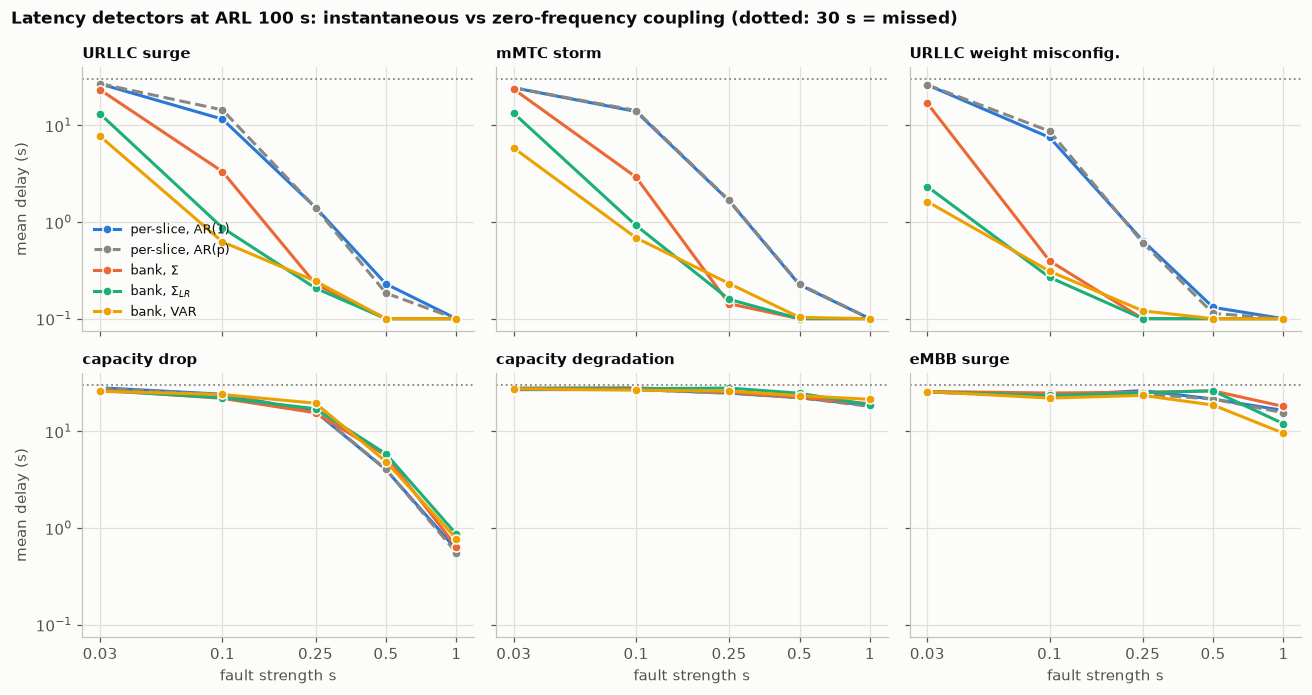

In [6]:
STYLE = {"per-slice, AR(1)": (BLUE, "-"), "per-slice, AR(p)": (MUTED, "--"), "bank, Sigma": (ORANGE, "-"),
         "bank, Sigma_LR": (AQUA, "-"), "bank, VAR": (YELLOW, "-")}
LABEL = {"bank, Sigma": r"bank, $\Sigma$", "bank, Sigma_LR": r"bank, $\Sigma_{LR}$"}
fig, axes = plt.subplots(2, 3, figsize=(12, 6.4), sharex=True, sharey=True)
for ax, scen in zip(axes.ravel(), USE):
    g = sweep[sweep.scenario == NICE[scen]]
    for det in DETS:
        d = g[g.detector == det].sort_values("strength")
        col, ls = STYLE[det]
        ax.plot(d.strength, d.delay_mean_s, marker="o", ls=ls, color=col, label=LABEL.get(det, det), mec=SURFACE, mew=1)
    ax.set_xscale("log"); ax.set_yscale("log")
    ax.axhline(30, color=MUTED, ls=":", lw=1.2)
    ax.set_title(NICE[scen], fontsize=10)
for ax in axes[1]:
    ax.set_xticks(STRENGTHS, [f"{s:g}" for s in STRENGTHS]); ax.minorticks_off()
    ax.set_xlabel("fault strength s")
for ax in axes[:, 0]:
    ax.set_ylabel("mean delay (s)")
axes[0, 0].legend(loc="lower left", fontsize=8.5)
fig.suptitle("Latency detectors at ARL 100 s: instantaneous vs zero-frequency coupling (dotted: 30 s = missed)",
             x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
save_fig(fig, "fig1_delay")
plt.show()

**What the sweep shows**

- **P1 holds: the $\Sigma_{LR}$ bank is much faster than the $\Sigma$ bank on slice-local faults.** At $s = 0.1$ the URLLC surge is found in 0.87 s instead of 3.3 s, and the mMTC storm in 0.92 s instead of 2.9 s. At $s = 0.03$, barely visible, it finds 80–100% of the local faults where the $\Sigma$ bank finds 41–75%.
- **P2 holds: the jointly whitened VAR bank is the best detector for local faults.** It finds 93–100% of faults at $s = 0.03$ (URLLC weight misconfiguration in 1.6 s on average, against 16.9 s for the $\Sigma$ bank and 26 s for per-slice). Only at large strengths, where every detector alarms within a few windows, is it slightly slower: its filter needs a few windows to settle.
- **P3 holds: richer per-slice whitening does not help.** AR(3) per slice is no faster than AR(1), and sometimes slower (URLLC surge at $s = 0.1$: 14.5 s against 11.6 s). Whatever one stream's filter, it cannot remove noise that only the other slices reveal.
- **Shared faults: coupling still does not help.** On capacity drops and degradations the banks are no better than per-slice detection, and for the capacity drop at $s = 0.25$ the VAR bank is worse (19.6 s, 65% found, against 15.9 s and 91%). A sustained shift common to all slices sits in exactly the slow common mode that the zero-frequency filter suppresses. The one shared exception is a full-strength eMBB surge, where the VAR bank is faster (9.6 s against 16.4 s).

## 4. Measured gain against the two theories

For each slice-local fault, the gain is the per-slice AR(1) delay divided by the coupled detector's delay. We use the weakest strength at which the per-slice detector still finds at least 80% of faults, so that capped misses do not dominate the ratio. We compare it with the instantaneous prediction $1/(1-R_j^2)$ and the zero-frequency one $1/(1-R^2_{j,\text{DC}})$ ($L = 50$).

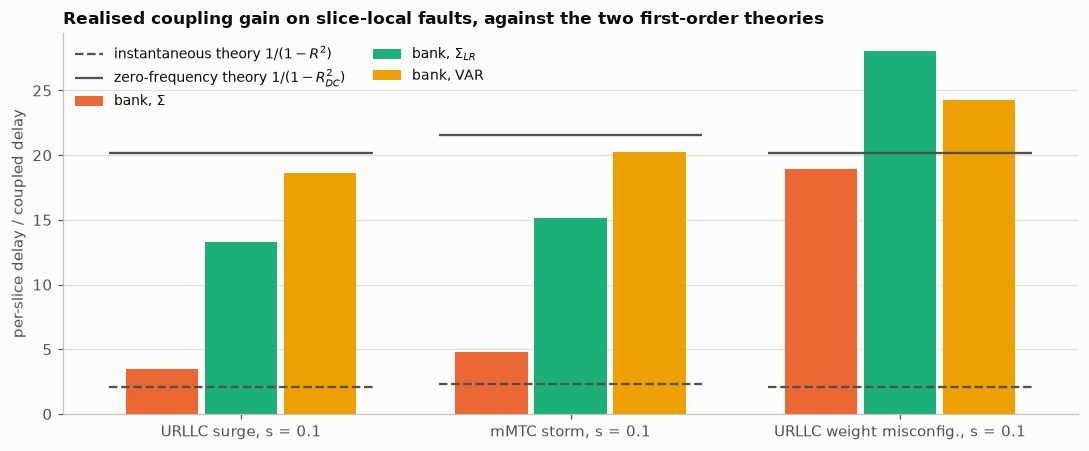

,scenario,strength,slice,"gain per-slice, AR(p)","gain bank, Sigma","gain bank, Sigma_LR","gain bank, VAR",instantaneous,zero_frequency
0,URLLC surge,0.1,URLLC,0.80,3.49,13.31,18.59,2.11,20.13
1,mMTC storm,0.1,mMTC,0.98,4.78,15.11,20.28,2.31,21.58
2,URLLC weight misconfig.,0.1,URLLC,0.86,18.93,28.02,24.23,2.11,20.13


In [7]:
piv = sweep.pivot_table(index=["scenario", "strength"], columns="detector", values="delay_mean_s")
det_ps = sweep[sweep.detector == "per-slice, AR(1)"].set_index(["scenario", "strength"]).detected
rows = []
for scen, j in LOCAL.items():
    ok = [s for s in STRENGTHS if det_ps[(NICE[scen], s)] >= 0.8]
    s = min(ok)
    p = piv.loc[(NICE[scen], s)]
    rows.append(dict(scenario=NICE[scen], strength=s, slice=SLICES[j],
                     **{f"gain {d}": p["per-slice, AR(1)"] / p[d] for d in DETS[1:]},
                     instantaneous=coh.instantaneous[j], zero_frequency=coh["DC, L = 50"][j]))
gains = pd.DataFrame(rows)
gains.to_csv(OUT / "gains.csv", index=False)

fig, ax = plt.subplots(figsize=(10, 4.2))
x = np.arange(len(gains))
bars = [("gain bank, Sigma", ORANGE, r"bank, $\Sigma$"), ("gain bank, Sigma_LR", AQUA, r"bank, $\Sigma_{LR}$"),
        ("gain bank, VAR", YELLOW, "bank, VAR")]
w = 0.22
for k, (colname, col, lab) in enumerate(bars):
    ax.bar(x + (k - 1) * (w + 0.02), gains[colname], width=w, color=col, label=lab)
for k in range(len(gains)):
    for val, ls, lab in [(gains.instantaneous[k], "--", "instantaneous theory $1/(1-R^2)$"),
                         (gains.zero_frequency[k], "-", "zero-frequency theory $1/(1-R^2_{DC})$")]:
        ax.hlines(val, k - 0.4, k + 0.4, color=INK2, ls=ls, lw=1.5, label=lab if k == 0 else None)
ax.set_xticks(x, [f"{a}, s = {b:g}" for a, b in zip(gains.scenario, gains.strength)])
ax.grid(axis="x", visible=False)
ax.set_ylabel("per-slice delay / coupled delay")
ax.set_title("Realised coupling gain on slice-local faults, against the two first-order theories")
ax.legend(loc="upper left", fontsize=9, ncol=2)
fig.tight_layout()
save_fig(fig, "fig2_gain_vs_theory")
plt.show()
gains.round(2)

In [8]:
# The same gains from MEDIAN delays, which do not depend on how misses are counted
med = sweep.pivot_table(index=["scenario", "strength"], columns="detector", values="delay_median_s")
mg = pd.DataFrame({d: med["per-slice, AR(1)"] / med[d] for d in DETS[1:]})
mg = mg.loc[[(NICE[s], v) for s in LOCAL for v in (0.1, 0.25)]]
mg.to_csv(OUT / "gains_median.csv")
mg.round(1)

per-slice, AR(p)  bank, Sigma  bank, Sigma_LR  bank, VAR
scenario                strength                                                          
URLLC surge             0.10                   0.8          5.1            14.1       16.5
                        0.25                   1.2          6.0             6.0        6.0
mMTC storm              0.10                   1.0          5.8            11.6       16.5
                        0.25                   1.0         14.5            14.5        7.3
URLLC weight misconfig. 0.10                   0.9         18.3            21.3       21.3
                        0.25                   1.0          5.0             5.0        5.0

**What Section 4 shows: the jointly whitened bank reaches the zero-frequency theory**

- **The VAR bank's realised gain at $s = 0.1$ is 18.6–24.2× (mean delay) and 16.5–21.3× (median).** The zero-frequency theory predicts 20–22 ($L = 50$), or 26–28 from the VAR. The instantaneous theory predicts 2.1–2.3, about ten times too little.
- **The $\Sigma_{LR}$ bank gets most of the way (13–28× mean, 12–21× median); the instantaneous $\Sigma$ bank gets 3.5–19×.** The $\Sigma$ bank does well only on the weight misconfiguration, where URLLC and mMTC move in *opposite* directions. That direction is far from the common mode at every frequency.
- **Richer per-slice whitening has gain 0.8–1.0**, i.e. none.
- **At $s = 0.25$ the medians compress** (5–15×) because the coupled detectors hit the one-window floor of 0.1 s.

So the numbers fit together: per-slice detection at its first-order limit, the $\Sigma$ bank in between, and the VAR bank at the zero-frequency limit.

## 5. Sensitivity of the $\Sigma_{LR}$ bank to the lag window

$\Sigma_{LR}$ is estimated, and with $R^2_{\text{DC}} \approx 0.95$ it is close to singular. So the bank's matched filter might depend strongly on the lag window $L$. We recalibrate the $\Sigma_{LR}$ bank with $L$ = 25 and 100 and rerun it on the same local-fault data.

In [9]:
t0 = time.time()
rows = []
for L in (25, 50, 100):
    b = CUSUMBank(C, SLR[L]); c, _ = calibrate_bank(b, Zcal, TARGET_ARL)
    for (scen, s), (Z, nu) in kept.items():
        if s not in (0.03, 0.1):
            continue
        t, _ = first_alarms(b, Z, c)
        rows.append(dict(scenario=NICE[scen], strength=s, L=L, **summarize_delays(t, nu, HORIZON_W, 0.1)))
sens = pd.DataFrame(rows)
sens.to_csv(OUT / "sensitivity_L.csv", index=False)
print(f"done in {time.time() - t0:.0f} s")
sens.pivot_table(index=["scenario", "strength"], columns="L", values="delay_mean_s").round(2)

done in 131 s


L                                   25     50     100
scenario                strength                     
URLLC surge             0.03      14.24  13.11  11.55
                        0.10       0.92   0.87   0.89
URLLC weight misconfig. 0.03       2.42   2.33   2.32
                        0.10       0.27   0.27   0.29
mMTC storm              0.03      14.88  13.34  11.70
                        0.10       0.92   0.92   0.91

**What Section 5 shows: the $\Sigma_{LR}$ bank is robust to the lag window.** Changing $L$ from 25 to 100 changes delays at $s = 0.1$ by at most 0.05 s, and at $s = 0.03$ by about ±12%, with larger $L$ slightly faster. The near-singularity of $\Sigma_{LR}$ does not make the detector fragile.

In [10]:
# Export tables and key numbers for report/main.tex
f2 = lambda v: "--" if pd.isna(v) else f"{v:.2f}"
f1 = lambda v: "--" if pd.isna(v) else f"{v:.1f}"
SHORT = {"per-slice, AR(1)": "per-slice AR(1)", "per-slice, AR(p)": "per-slice AR($p$)", "bank, Sigma": r"bank $\Sigma$",
         "bank, Sigma_LR": r"bank $\Sigma_{LR}$", "bank, VAR": "bank VAR"}
rows = []
for scen in USE:
    for s in STRENGTHS:
        r = {"fault": NICE[scen], "$s$": f"{s:g}"}
        for d in DETS:
            g = sweep[(sweep.scenario == NICE[scen]) & (sweep.strength == s) & (sweep.detector == d)].iloc[0]
            r[SHORT[d]] = f"{g.delay_mean_s:.1f}" if g.detected >= 0.995 else f"{g.delay_mean_s:.1f} ({100 * g.detected:.0f}\\%)"
        rows.append(r)
tab = pd.DataFrame(rows)
tab["fault"] = [f if i == 0 or f != tab.fault[i - 1] else "" for i, f in enumerate(tab.fault)]
save_tex_table(tab, "sweep", "llrrrrr")

t = coh.copy()
for c in t.columns[1:]:
    t[c] = t[c].map(f1)
t.columns = ["slice", "instantaneous", "DC, $L=25$", "DC, $L=50$", "DC, $L=100$", "DC, VAR-implied"]
save_tex_table(t, "coherence", "lrrrrr")

t = gains[["scenario", "strength", "slice", "gain per-slice, AR(p)", "gain bank, Sigma", "gain bank, Sigma_LR",
           "gain bank, VAR", "instantaneous", "zero_frequency"]].copy()
t["strength"] = t.strength.map(lambda v: f"{v:g}")
for c in t.columns[3:]:
    t[c] = t[c].map(f1)
t.columns = ["fault", "$s$", "slice", "AR($p$)", r"bank $\Sigma$", r"bank $\Sigma_{LR}$", "bank VAR",
             "theory, inst.", "theory, DC"]
save_tex_table(t, "gains", "llcrrrrrr")

P = piv
loc = lambda scen, s, d: P.loc[(NICE[scen], s), d]
G = gains.set_index("scenario")
save_tex_numbers({
    "LrOrderArp": f"{arp.p}", "LrOrderVar": f"{var.p}",
    "LrDcUrllc": f1(coh['DC, L = 50'][1]), "LrDcMmtc": f1(coh['DC, L = 50'][2]),
    "LrDcVarUrllc": f1(coh['DC, VAR-implied'][1]), "LrDcVarMmtc": f1(coh['DC, VAR-implied'][2]),
    "LrInstUrllc": f1(coh.instantaneous[1]), "LrInstMmtc": f1(coh.instantaneous[2]),
    "LrGainSigmaMin": f1(gains['gain bank, Sigma'].min()), "LrGainSigmaMax": f1(gains['gain bank, Sigma'].max()),
    "LrGainLrMin": f1(gains['gain bank, Sigma_LR'].min()), "LrGainLrMax": f1(gains['gain bank, Sigma_LR'].max()),
    "LrGainVarMin": f1(gains['gain bank, VAR'].min()), "LrGainVarMax": f1(gains['gain bank, VAR'].max()),
    "LrGainArpMin": f2(gains['gain per-slice, AR(p)'].min()), "LrGainArpMax": f2(gains['gain per-slice, AR(p)'].max()),
    "LrWeakSigma": f1(loc("urllc_weight_misconfig", 0.03, "bank, Sigma")),
    "LrWeakLr": f1(loc("urllc_weight_misconfig", 0.03, "bank, Sigma_LR")),
    "LrWeakVar": f1(loc("urllc_weight_misconfig", 0.03, "bank, VAR")),
    "LrWeakPer": f1(loc("urllc_weight_misconfig", 0.03, "per-slice, AR(1)")),
})
print("exported:", sorted(p.name for p in (REPORT / "tables").glob("10_*")))

exported: ['10_coherence.tex', '10_gains.tex', '10_numbers.tex', '10_sweep.tex']


## Summary

- **All three predictions of the zero-frequency theory hold.**
  - P1: a bank built on $\Sigma_{LR}$ is 1.5–3.8× faster than the instantaneous bank on slice-local faults at $s = 0.1$, and up to 7× at $s = 0.03$.
  - P2: jointly whitening the slices with a VAR(3) and running the bank on its innovations is faster still. Its realised gain over per-slice CUSUM, about 17–24×, matches the predicted $1/(1-R^2_{\text{DC}}) \approx 20$.
  - P3: richer per-slice whitening gives nothing; the gap is not an artefact of a weak baseline.
- **The best detector is not new.** Charting VAR residuals with a multivariate CUSUM is established in process control, and long-run covariance is standard in econometric monitoring. Our candidate contribution is therefore not a detector, but:
  1. **a measurement:** under shared-resource slicing, slice KPIs are only moderately correlated instant by instant ($R^2 \approx 0.5$) but almost perfectly coherent at low frequency ($R^2_{\text{DC}} \approx 0.95$);
  2. **a design rule:** the value of coupling for a sustained fault is set by $1/(1-R^2_{\text{DC}})$. Instantaneous correlation, the usual way to reason about it, underestimates it by about 10×;
  3. **the evidence:** simulated, fault-labelled 5G slicing with every detector at a common ARL, including the faults where coupling does *not* help (shared capacity faults).
- **Still to do before a paper:**
  - the same result at a second load and slice mix;
  - a check that the design rule holds there too (does $1/(1-R^2_{\text{DC}})$ predict the measured gain?);
  - ML baselines at the same ARL;
  - full-text reading of the closest prior art.
- **For the demo and combined detector:** replacing the $\Sigma$ bank with the VAR bank should improve local-fault detection a lot and leave shared faults unchanged. That is a separate change, not made here.